In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt

In [2]:
housing= pd.read_csv("HousingData.csv")

In [3]:
housing.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,NaN,36.2


## Dependent feature distribution

housing.MEDV.hist()

#### If p > 0.05 then null hypothesis else alternative

In [5]:
from scipy.stats import normaltest 

In [6]:
normaltest(housing.MEDV.values)

NormaltestResult(statistic=np.float64(90.9746873700967), pvalue=np.float64(1.7583188871696098e-20))

## Testing log

In [7]:
log_medv= np.log(housing.MEDV)

NormaltestResult(statistic=np.float64(17.21801696640698), pvalue=np.float64(0.00018245472768345196))

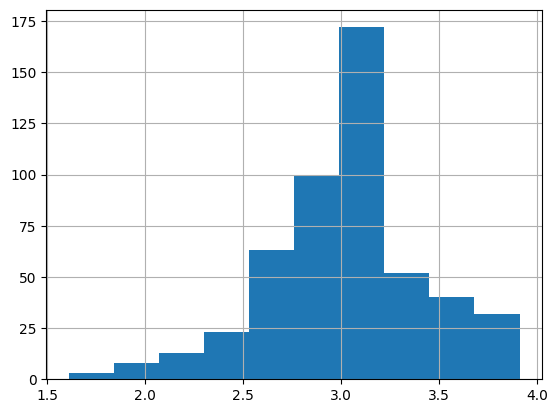

In [8]:
log_medv.hist()
normaltest(log_medv.values)

## Sqrt Trf

In [9]:
sqrt_medv= np.sqrt(housing.MEDV)

NormaltestResult(statistic=np.float64(20.487090826863067), pvalue=np.float64(3.558645701429252e-05))

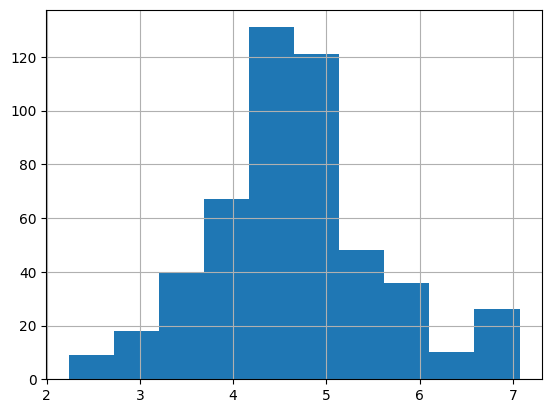

In [10]:
sqrt_medv.hist()
normaltest(sqrt_medv.values)

## Box cox Trf

In [11]:
from scipy.stats import boxcox

In [12]:
bc= boxcox(housing.MEDV)
boxcox_medv= bc[0]
lam= bc[1]

NormaltestResult(statistic=np.float64(4.513528737272378), pvalue=np.float64(0.10468867128448933))


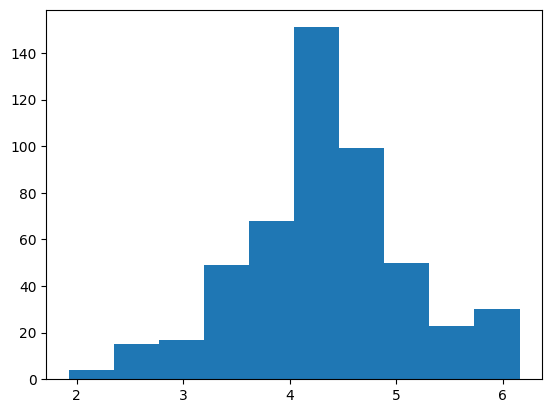

In [13]:
print(normaltest(boxcox_medv))
plt.hist(boxcox_medv)
plt.show()

In [14]:
from scipy.stats import yeojohnson

In [15]:
yeojo = yeojohnson(housing.MEDV)
yeojo_medv= yeojo[0]
yeojo_lmda= yeojo[1]

NormaltestResult(statistic=np.float64(4.19627380716702), pvalue=np.float64(0.12268478904867047))


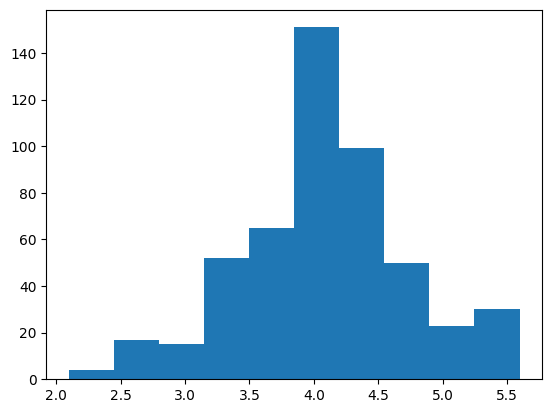

In [16]:
print(normaltest(yeojo_medv))
plt.hist(yeojo_medv)
plt.show()

In [54]:
null_cols= [i for i in housing.columns if housing[i].isnull().sum() >0]

for i in null_cols:
    housing.fillna({i: housing[i].median()}, inplace= True)

housing.isnull().sum()

CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64

## Model Training

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

In [56]:
lr = LinearRegression()

In [119]:
X= housing.drop("MEDV", axis=1)
y= housing["MEDV"]

### Polynomial Features

In [121]:
pf = PolynomialFeatures(degree=2, include_bias=False)
x_pf= pf.fit_transform(X)

#### Train Test split

In [122]:
x_train, x_test, y_train, y_test= train_test_split(x_pf, y, test_size=.3, random_state=72018)

364    21.9
281    35.4
112    18.8
218    21.5
72     22.8
       ... 
150    21.5
307    28.2
42     25.3
10     15.0
136    17.4
Name: MEDV, Length: 354, dtype: float64

#### Fit StandardScaler on x_train

In [75]:
s= StandardScaler()
x_train_scaled= s.fit_transform(x_train)
x_test_sclaed= s.transform(x_test)

#### Applying Power Transformer Yeojohnson

In [138]:
bc= boxcox(y_train)
y_train_bc= bc[0]
lam_bc = bc[1]

In [140]:
lr.fit(x_train_scaled, y_train_bc)
y_pred= lr.predict(x_test_sclaed)

Because of target variable y having different scale we inverse transform
### Inverse transformation

In [142]:
from scipy.special import inv_boxcox

In [149]:
y_pred_trf= inv_boxcox(y_pred, lam_bc)

### R2 score

In [152]:
r2_score(y_pred_trf, y_test)

0.6884413706670567

In [160]:
lr= LinearRegression()
lr.fit(x_train_scaled, y_train)

y_pred= lr.predict(x_test_sclaed)

r2_score(y_pred, y_test)

0.6690456098829534